# 02 — Baselines

Quatro baselines da aula, ajustados **só no treino** e avaliados nos 28 dias de validação. A implementação está em `src/ts_utils.py`, a mesma usada pelo `run.py`, para que notebook e `metricas.csv` não divirjam.

- **média:** média histórica do treino.
- **naive:** último valor do treino.
- **naive sazonal (m=7):** repete a última semana do treino.
- **drift:** reta entre a primeira e a última observação do treino.

**Sem vazamento:** cada baseline usa só `y_train` (média, último valor, última semana, primeiro e último ponto). A validação serve apenas para calcular o erro.

In [1]:
import sys
from pathlib import Path

RAIZ = Path.cwd().resolve().parents[1]  # notebook roda a partir de src/entrega_1
sys.path.insert(0, str(RAIZ / "src"))
sys.path.insert(0, str(RAIZ))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from ts_utils import BASELINES, M, SERIES, calcular_baselines, calcular_metricas, carregar_dados, escala_mase

treino, val = carregar_dados(RAIZ)
h = len(val)
print(f"Treino: {treino.date.min().date()} a {treino.date.max().date()} ({len(treino)} dias)")
print(f"Validação: {val.date.min().date()} a {val.date.max().date()} ({h} dias)")

Treino: 2011-01-29 a 2016-03-27 (1885 dias)
Validação: 2016-03-28 a 2016-04-24 (28 dias)


## Previsões e métricas

MASE com escala = MAE in-sample do naive sazonal (m=7) no treino.

In [2]:
linhas = []
prev = {}
for s in SERIES:
    y_tr, y_va = treino[s].to_numpy(float), val[s].to_numpy(float)
    prev[s] = calcular_baselines(y_tr, h=h, m=M)
    for modelo, yhat in prev[s].items():
        mae, rmse, mase = calcular_metricas(y_tr, y_va, yhat)
        linhas.append({"series": s, "modelo": modelo, "mae": mae, "rmse": rmse, "mase": mase})
metricas_baselines = pd.DataFrame(linhas)
metricas_baselines.round(3)

,series,modelo,mae,rmse,mase
0,store_total,media,813.885,1109.595,1.871
1,store_total,naive,862.750,966.632,1.983
2,store_total,naive_sazonal,459.179,655.467,1.056
3,store_total,drift,863.279,966.756,1.984
4,FOODS,media,526.929,671.830,1.540
5,FOODS,naive,664.643,722.859,1.943
6,FOODS,naive_sazonal,343.857,420.116,1.005
7,FOODS,drift,664.965,723.257,1.944
8,HOBBIES,media,110.995,141.305,1.216
9,HOBBIES,naive,169.036,204.728,1.851


## Conferência com o `metricas.csv` oficial

In [3]:
oficial = pd.read_csv(RAIZ / "metricas.csv")
oficial = oficial[oficial.modelo.isin(BASELINES)].reset_index(drop=True)
assert np.allclose(oficial[["mae", "rmse", "mase"]], metricas_baselines[["mae", "rmse", "mase"]])
print("OK: baselines do notebook = baselines de metricas.csv")

OK: baselines do notebook = baselines de metricas.csv


## Gráfico

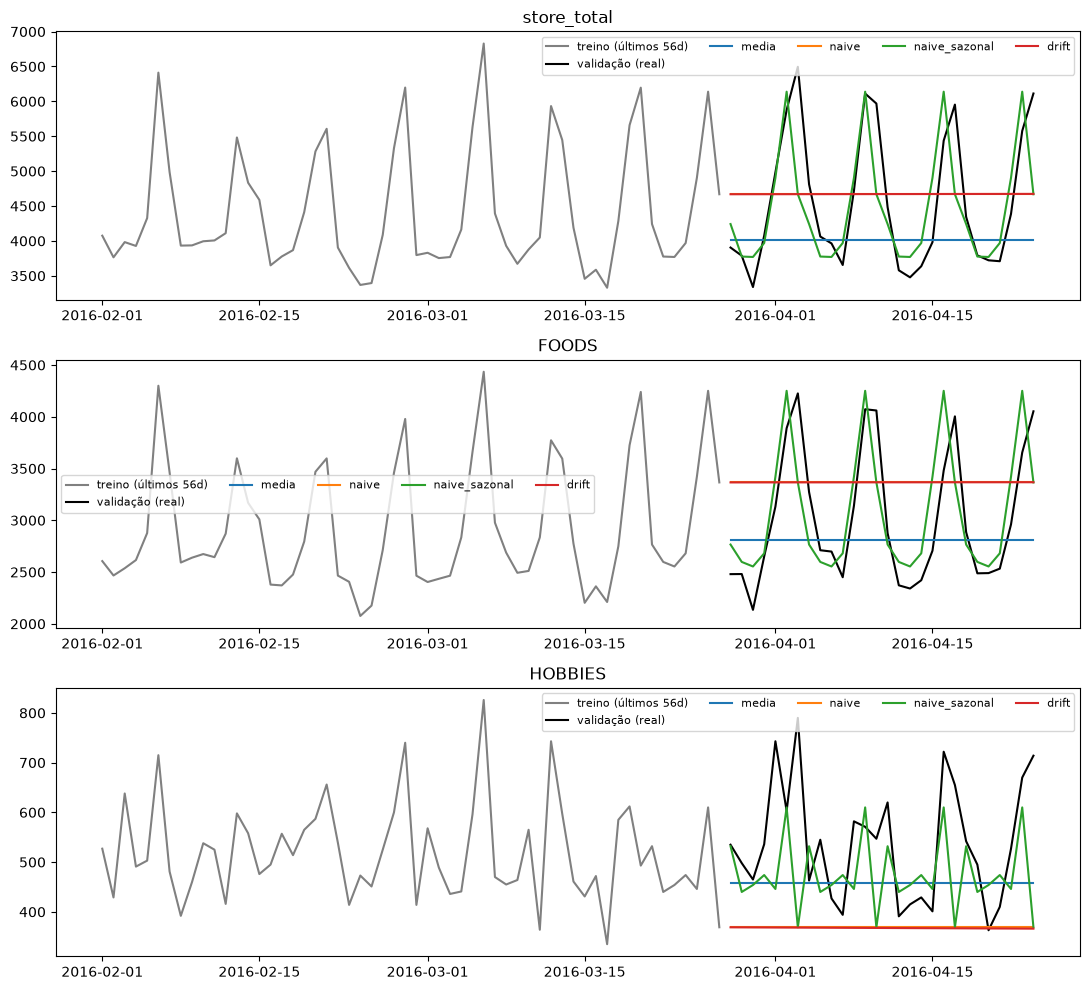

In [4]:
fig, ax = plt.subplots(3, 1, figsize=(11, 10))
for a, s in zip(ax, SERIES):
    a.plot(treino.date.tail(56), treino[s].tail(56), color="gray", label="treino (últimos 56d)")
    a.plot(val.date, val[s], color="black", label="validação (real)")
    for modelo, yhat in prev[s].items():
        a.plot(val.date, yhat, label=modelo)
    a.set_title(s); a.legend(ncol=5, fontsize=8)
fig.tight_layout()

## Leitura

`naive` e `drift` ignoram a sazonalidade semanal e ficam com MASE ≈ 1,9–2,0 nas três séries; o drift é quase idêntico ao naive porque a inclinação do treino é minúscula. A média perde para o naive sazonal em `store_total` e `FOODS`; em `HOBBIES` o naive sazonal tem MAE menor e a média tem RMSE menor, e ambos têm MASE > 1. Comparação com o SARIMA em `03_arima_sarima.ipynb` e `RESULTADOS.md`.